Hier wat eerste probeersels om een beetje vat op de stof te krijgen. Om te beginnen ga ik bezig met workshop 1; differentiaalvergelijkingen. Hier is de volgende code bijgeleverd:

<math xmlns="http://www.w3.org/1998/Math/MathML" display="block">
  <mrow data-mjx-texclass="INNER">
    <mo data-mjx-texclass="OPEN">{</mo>
    <mtable displaystyle="true" columnalign="right left" columnspacing="0em" rowspacing="3pt">
      <mtr>
        <mtd>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>S</mi>
        </mtd>
        <mtd>
          <mi></mi>
          <mo>&#x2248;</mo>
          <mo>&#x2212;</mo>
          <mi>&#x3B2;</mi>
          <mi>S</mi>
          <mi>I</mi>
          <mo>&#x22C5;</mo>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>t</mi>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>I</mi>
        </mtd>
        <mtd>
          <mi></mi>
          <mo>&#x2248;</mo>
          <mrow data-mjx-texclass="INNER">
            <mo data-mjx-texclass="OPEN">(</mo>
            <mo>+</mo>
            <mi>&#x3B2;</mi>
            <mi>S</mi>
            <mi>I</mi>
            <mo>&#x2212;</mo>
            <mi>&#x3B3;</mi>
            <mi>I</mi>
            <mo data-mjx-texclass="CLOSE">)</mo>
          </mrow>
          <mo>&#x22C5;</mo>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>t</mi>
        </mtd>
      </mtr>
      <mtr>
        <mtd>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>R</mi>
        </mtd>
        <mtd>
          <mi></mi>
          <mo>&#x2248;</mo>
          <mo>+</mo>
          <mi>&#x3B3;</mi>
          <mi>I</mi>
          <mo>&#x22C5;</mo>
          <mi mathvariant="normal">&#x394;</mi>
          <mi>t</mi>
        </mtd>
      </mtr>
    </mtable>
    <mo data-mjx-texclass="CLOSE" fence="true" stretchy="true" symmetric="true"></mo>
  </mrow>
</math>

In [1]:
from matplotlib import pyplot as plt

def SIRmodel(beta=0.25, gamma=0.10, N=365, delta_t=1.0):

    """Integreert het SIR-model voor gegeven beta en gamma
    over N integratiestappen ter grootte van delta_t,
    startend met een infectiegraad van 1 op 10000.
    Parameters:
      beta (float):     infectiesnelheid (per dag)
      gamma (float):    herstelsnelheid (per dag)
      N (int):          aantal integratiestappen
      delta_t (float):  stapgrootte
    Retourneert:
      ts (list[float]): lijst met tijdstippen (dag)
      Ss (list[float]): lijst met Susceptible fracties
      Is (list[float]): lijst met Infectious fracties
      Rs (list[float]): lijst met Recovered fracties
    """
    t = 0.0
    ts = [t]
    S, I, R = 0.9999, 0.0001, 0.0000
    Ss, Is, Rs = [S], [I], [R]
    for _ in range(N):
        infections = beta * S * I * delta_t
        recoveries = gamma * I * delta_t
        t = t + delta_t
        S = S - infections
        I = I + infections - recoveries
        R = R + recoveries
        ts.append(t)
        Ss.append(S)
        Is.append(I)
        Rs.append(R)
    return ts, Ss, Is, Rs

def plot(ts, Ss, Is, Rs):
    """Plot de resultaten van het SIR-model.
    Parameters:
      ts (list[float]): lijst met tijdstippen (dag)
      Ss (list[float]): lijst met Susceptible fracties
      Is (list[float]): lijst met Infectious fracties
      Rs (list[float]): lijst met Recovered fracties
    """
    plt.figure(figsize=(12.8, 4.8))
    plt.axvline(0.0, color='k')
    plt.plot(ts, Ss, label="Susceptible $S(t)$")
    plt.plot(ts, Is, label="Infectious $I(t)$")
    plt.plot(ts, Rs, label="Recovered $R(t)$")
    plt.title('SIR-model'); plt.xlabel('$t$ [d]'); plt.ylabel('$y$ [-]'); 
    plt.ylim((-0.005, 1.005)); plt.grid(True); plt.legend()
    plt.show()

Matplotlib is building the font cache; this may take a moment.


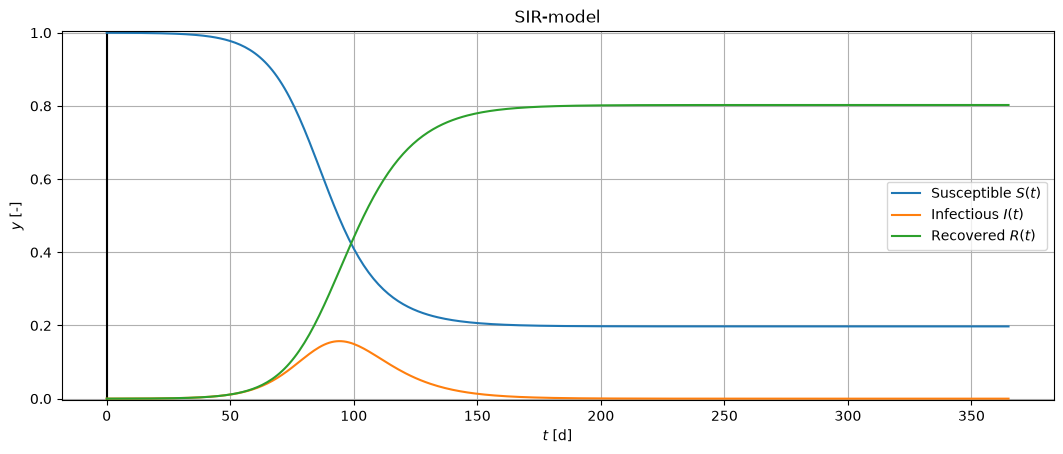

In [8]:
plot(*SIRmodel(beta=0.2))

Nu dit overgenomen en functionerend heb, kan makkelijk aan de hand van beta & gamma er veranderingen aangebracht worden.

In [2]:
from math import exp

Nsteps = 5
dt = 1.0 / Nsteps

# Voorbeeld differentiaalvergelijking: dy/dt = y + 1
def ODE(t, y):
    return y + 1.0

# Heeft met beginwaarde y(0)=0 als wiskundige oplossing: y(t) = e^t - 1
def solution(t):
    return exp(t) - 1.0
ts_exact = [i * dt for i in range(Nsteps+1)]
ys_exact = [solution(t) for t in ts_exact]

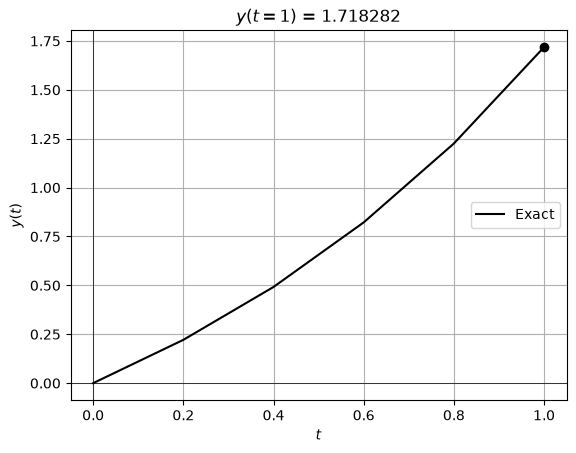

In [3]:
from matplotlib import pyplot as plt

plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_exact[-1], ys_exact[-1], 'ok')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'$y(t=1)$ = {ys_exact[-1]:8.6f}')
plt.show()

In [4]:
# Initialisatie
t, y = 0.0, 0.0
ts_euler, ys_euler = [t], [y]

# ODE-solver
for _ in range(Nsteps):
    # Update volgens Euler
    dydt1 = ODE(t, y)
    t = t + dt
    y = y + dydt1 * dt
    # Bewaar tussenresultaten
    ts_euler.append(t)
    ys_euler.append(y)

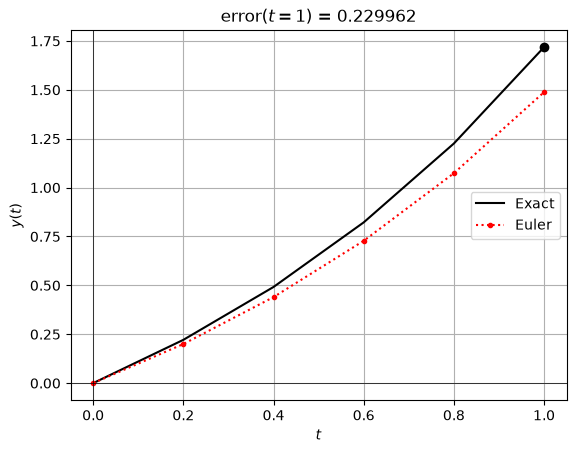

In [5]:
plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_exact[-1], ys_exact[-1], 'ok')
plt.plot(ts_euler, ys_euler, '.:r', label='Euler')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'error$(t=1)$ = {ys_exact[-1] - ys_euler[-1]:8.6f}')
plt.show()

In [6]:
# Initialisatie
t, y = 0.0, 0.0
ts_heun, ys_heun = [t], [y]

# ODE-solver
for _ in range(Nsteps):
    # Eerste update
    dydt1 = ODE(t, y)
    t1 = t + dt
    y1 = y + dydt1 * dt
    # Tweede update volgens Heun
    dydt2 = ODE(t1, y1)
    t = t + dt
    y = y + (dydt1 + dydt2) / 2.0 * dt
    # Bewaar tussenresultaten
    ts_heun.append(t)
    ys_heun.append(y)

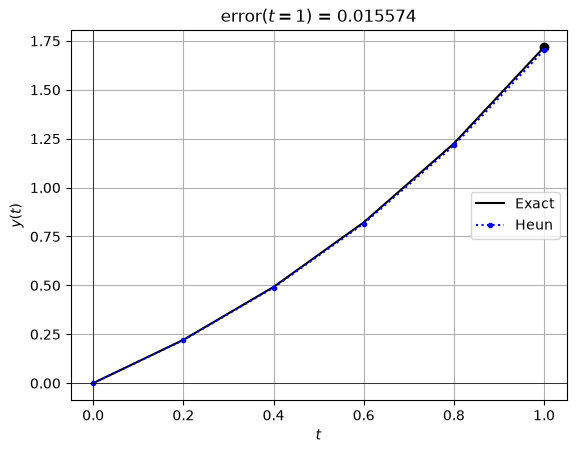

In [7]:
plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_exact[-1], ys_exact[-1], 'ok')
plt.plot(ts_heun, ys_heun, '.:b', label='Heun')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'error$(t=1)$ = {ys_exact[-1] - ys_heun[-1]:8.6f}')
plt.show()

In [8]:
# Initialisatie
t, y = 0.0, 0.0
ts_rungekutta, ys_rungekutta = [t], [y]

# ODE-solver
for _ in range(Nsteps):
    # Eerste update
    dydt1 = ODE(t, y)
    t1 = t + 0.5 * dt
    y1 = y + 0.5 * dydt1 * dt
    # Tweede update
    dydt2 = ODE(t1, y1)
    t2 = t + 0.5 * dt
    y2 = y + 0.5 * dydt2 * dt
    # Derde update
    dydt3 = ODE(t2, y2)
    t3 = t + dt
    y3 = y + dydt2 * dt
    # Vierde update volgens Runge-Kutta
    dydt4 = ODE(t3, y3)
    t = t + dt
    y = y + (dydt1 + 2.0 * dydt2 + 2.0 * dydt3 + dydt4) / 6.0 * dt
    # Bewaar tussenresultaten
    ts_rungekutta.append(t)
    ys_rungekutta.append(y)

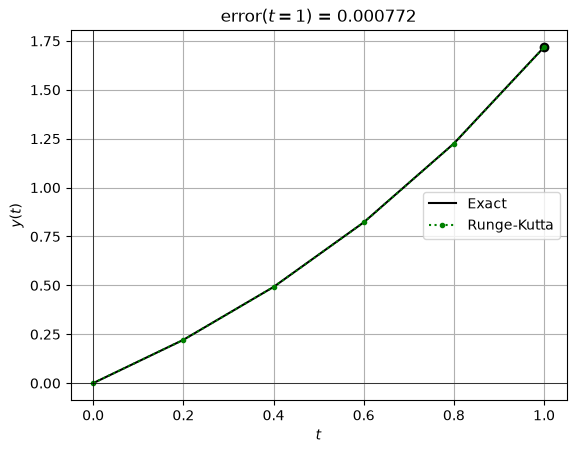

In [9]:
plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_exact[-1], ys_exact[-1], 'ok')
plt.plot(ts_rungekutta, ys_rungekutta, '.:g', label='Runge-Kutta')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'error$(t=1)$ = {ys_exact[-1] - ys_rungekutta[-1]:8.6f}')
plt.show()

## Optimalisatie

In [17]:
from math import exp

Nsteps = 20
dt = 1.0 / Nsteps

ts_exact = [i * dt for i in range(Nsteps+1)]
ys_exact = [exp(t) - 1.0 for t in ts_exact]

In [18]:
def compute_curve(a, b, y0):

    def ODE(t, y):
        return a * y + b   # <- het model heeft nu 2 parameters
    
    t, y = 0.0, y0         # <- de beginwaarde y(0) is ook een parameter
    ts, ys = [t], [y]
    for _ in range(Nsteps):
        # Eerste update
        dydt1 = ODE(t, y)
        t1 = t + 0.5 * dt
        y1 = y + 0.5 * dydt1 * dt
        # Tweede update
        dydt2 = ODE(t1, y1)
        t2 = t + 0.5 * dt
        y2 = y + 0.5 * dydt2 * dt
        # Derde update
        dydt3 = ODE(t2, y2)
        t3 = t + dt
        y3 = y + dydt2 * dt
        # Vierde update volgens Runge-Kutta
        dydt4 = ODE(t3, y3)
        t = t + dt
        y = y + (dydt1 + 2.0 * dydt2 + 2.0 * dydt3 + dydt4) / 6.0 * dt
        # Bewaar tussenresultaten
        ts.append(t)
        ys.append(y) 
    return ts, ys

params = {
    'a':  1.0,
    'b':  1.0,
    'y0': 0.0,
}


In [19]:
def MSE(a, b, y0):
    _, ys_model = compute_curve(a, b, y0)
    sum_squared_error = 0.0
    for y_exact, y_model in zip(ys_exact, ys_model):
        error = y_exact - y_model
        sum_squared_error += error * error
    mean_squared_error = sum_squared_error / len(ys_model)
    return mean_squared_error

print(f'MSE = {MSE(**params):.2e}')

MSE = 4.26e-11


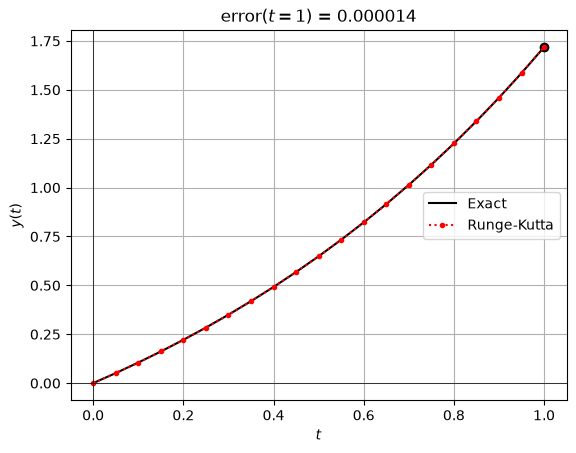

In [20]:

ts_numer, ys_numer = compute_curve(**params)

plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_exact[-1], ys_exact[-1], 'ok')
plt.plot(ts_numer, ys_numer, '.:r', label='Runge-Kutta')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'error$(t=1)$ = {ys_exact[-1] - ys_numer[-1]:8.6f}')
plt.show()

In [21]:
from random import gauss

# Initialisatie van onbekende waarden
params = {
    'a':  0.0,
    'b':  0.0,
    'y0': 0.0,
}

# Herhaaldelijke aanpassing
mse = MSE(**params)
tries = 0
while tries < 1000:
    tries += 1
    new_params = {key: val + gauss(sigma=0.01) for key, val in params.items()}
    new_mse = MSE(**new_params)
    if new_mse < mse:
        params = new_params
        mse = new_mse
        tries = 0

In [22]:
print('Optimale parameters:')
for key, val in params.items():
    print(f'* {key:>2s} = {val:9.6f}')

Optimale parameters:
*  a =  0.994140
*  b =  1.002534
* y0 = -0.000106


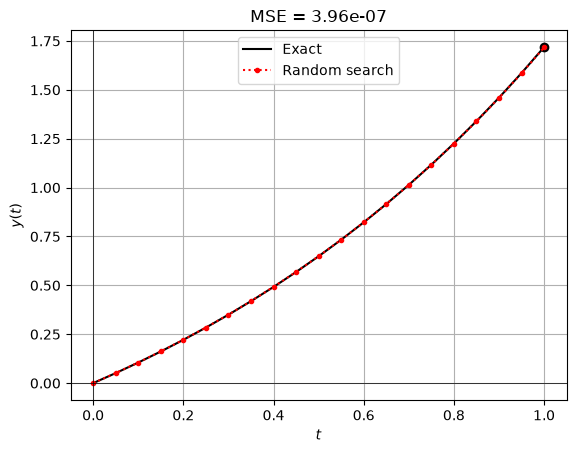

In [23]:
ts_numer, ys_numer = compute_curve(**params)

plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_exact[-1], ys_exact[-1], 'ok')
plt.plot(ts_numer, ys_numer, '.:r', label='Random search')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'MSE = {mse:8.2e}')
plt.show()

In [24]:
# Initialisatie van onbekende waarden
params = {
    'a':  0.0,
    'b':  0.0,
    'y0': 0.0,
}
deltas = {key: 1.0 for key in params}

# Herhaaldelijke aanpassing
mse = MSE(**params)
while max(abs(delta) for delta in deltas.values()) > 1e-9:
    for key in params:
        new_params = params.copy()
        # Probeer de betreffende parameter the verhogen
        new_params[key] = params[key] + deltas[key]
        new_mse = MSE(**new_params)
        if new_mse < mse:
            params = new_params
            mse = new_mse
            deltas[key] *= 1.2
            continue
        # Probeer de betreffende parameter the verlagen
        new_params[key] = params[key] - deltas[key]
        new_mse = MSE(**new_params)
        if new_mse < mse:
            params = new_params
            mse = new_mse
            deltas[key] *= -1.2
            continue
        # Verklein de stapgrootte
        deltas[key] *= 0.2

In [25]:
print('Optimale parameters:')
for key, val in params.items():
    print(f'* {key:>2s} = {val:9.6f}')

Optimale parameters:
*  a =  1.000004
*  b =  1.000005
* y0 = -0.000000


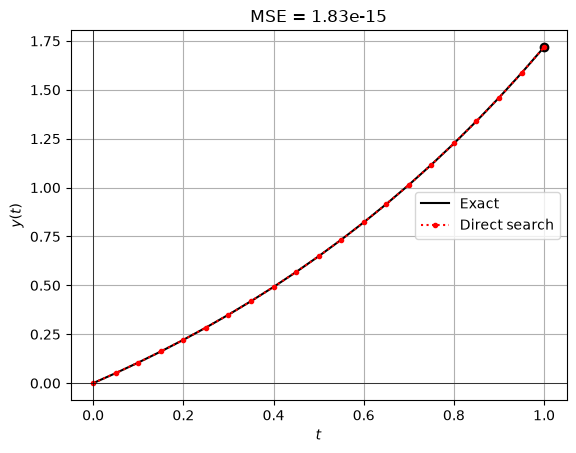

In [26]:
ts_numer, ys_numer = compute_curve(**params)

plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_exact[-1], ys_exact[-1], 'ok')
plt.plot(ts_numer, ys_numer, '.:r', label='Direct search')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'MSE = {mse:8.2e}')
plt.show()

## Modelvergelijking

In [27]:
from math import exp, log
from random import gauss

Nsteps = 20
dt = 1.0 / Nsteps

ts_exact = [i * dt for i in range(Nsteps+1)]
ys_exact = [exp(t) - 1.0 for t in ts_exact]

ts_data = ts_exact
ys_data = [y + gauss(sigma=0.01) for y in ys_exact]

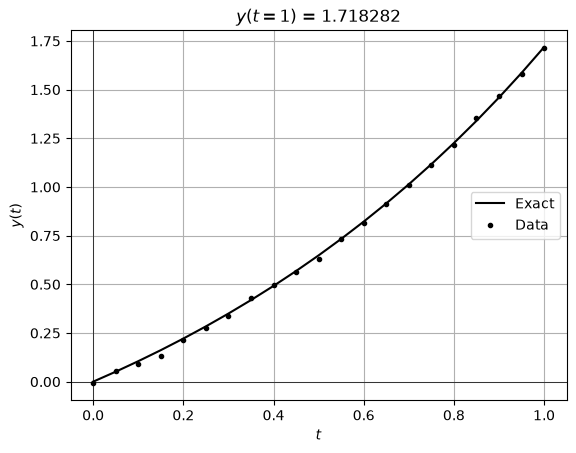

In [28]:
from matplotlib import pyplot as plt

plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_data, ys_data, '.k', label='Data')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'$y(t=1)$ = {ys_exact[-1]:8.6f}')
plt.show()

In [29]:
def compute_curve(a, b, y0):

    def ODE(t, y):
        return a * y + b
    
    t, y = 0.0, y0
    ts, ys = [t], [y]
    for _ in range(Nsteps):
        dydt1 = ODE(t, y)
        dydt2 = ODE(t + 0.5 * dt, y + 0.5 * dydt1 * dt)
        dydt3 = ODE(t + 0.5 * dt, y + 0.5 * dydt2 * dt)
        dydt4 = ODE(t + dt, y + dydt2 * dt)
        t, y = t + dt, y + (dydt1 + 2.0 * dydt2 + 2.0 * dydt3 + dydt4) / 6.0 * dt
        ts.append(t)
        ys.append(y) 
    return ts, ys

def MSE(a, b, y0):
    _, ys_model = compute_curve(a, b, y0)
    mse = sum((y_data-y_model)**2 for y_data, y_model in zip(ys_data, ys_model)) / len(ys_model)
    return mse

def pattern_search():
    params = {'a':  0.0, 'b':  0.0, 'y0': 0.0}
    deltas = {key: 1.0 for key in params}
    mse = MSE(**params)
    while max(abs(delta) for delta in deltas.values()) > 1e-9:
        for key in params:
            new_params = params.copy()
            new_params[key] = params[key] + deltas[key]
            new_mse = MSE(**new_params)
            if new_mse < mse:
                params, mse = new_params, new_mse
                deltas[key] *= 1.2
                continue
            new_params[key] = params[key] - deltas[key]
            new_mse = MSE(**new_params)
            if new_mse < mse:
                params, mse = new_params, new_mse
                deltas[key] *= -1.2
                continue
            deltas[key] *= 0.2
    return params

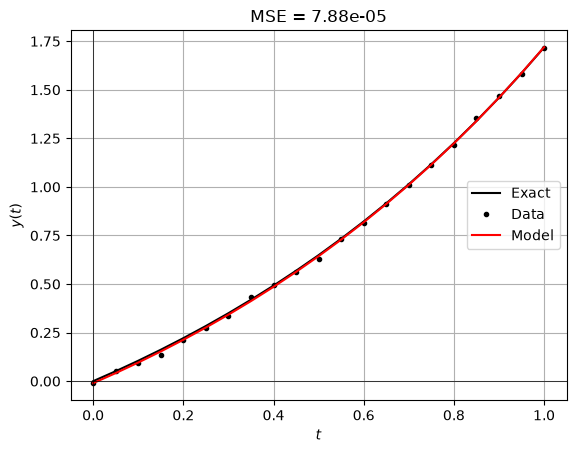

In [31]:
params = pattern_search()
ts_model, ys_model = compute_curve(**params)
mse = MSE(**params)

plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_data, ys_data, '.k', label='Data')
plt.plot(ts_model, ys_model, '-r', label='Model')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'MSE = {mse:8.2e}')
plt.show()

In [32]:
n, k = len(ys_model), len(params)
BIC  = n * log(mse) + k * log(n)
AIC  = n * log(mse) + k * 2.0
AICc = n * log(mse) + k * 2.0 * n/(n-k-1)

print("MODEL: dy/dt = a * y + b")
for key, val in params.items():
    print(f'* {key:>2s} = {val:9.6f}')
print(f"{BIC  = :.1f}")
print(f"{AIC  = :.1f}")
print(f"{AICc = :.1f}")

MODEL: dy/dt = a * y + b
*  a =  0.996626
*  b =  1.018828
* y0 = -0.010173
BIC  = -189.3
AIC  = -192.4
AICc = -191.0


In [33]:
def compute_curve(a, b, c, y0):

    def ODE(t, y):
        return a * y*y + b * y + c
    
    t, y = 0.0, y0
    ts, ys = [t], [y]
    for _ in range(Nsteps):
        dydt1 = ODE(t, y)
        dydt2 = ODE(t + 0.5 * dt, y + 0.5 * dydt1 * dt)
        dydt3 = ODE(t + 0.5 * dt, y + 0.5 * dydt2 * dt)
        dydt4 = ODE(t + dt, y + dydt2 * dt)
        t, y = t + dt, y + (dydt1 + 2.0 * dydt2 + 2.0 * dydt3 + dydt4) / 6.0 * dt
        ts.append(t)
        ys.append(y) 
    return ts, ys

def MSE(a, b, c, y0):
    _, ys_model = compute_curve(a, b, c, y0)
    mse = sum((y_data-y_model)**2 for y_data, y_model in zip(ys_data, ys_model)) / len(ys_model)
    return mse

def pattern_search():
    params = {'a':  0.0, 'b':  0.0, 'c':  0.0, 'y0': 0.0}
    deltas = {key: 1.0 for key in params}
    mse = MSE(**params)
    while max(abs(delta) for delta in deltas.values()) > 1e-9:
        for key in params:
            new_params = params.copy()
            new_params[key] = params[key] + deltas[key]
            new_mse = MSE(**new_params)
            if new_mse < mse:
                params, mse = new_params, new_mse
                deltas[key] *= 1.2
                continue
            new_params[key] = params[key] - deltas[key]
            new_mse = MSE(**new_params)
            if new_mse < mse:
                params, mse = new_params, new_mse
                deltas[key] *= -1.2
                continue
            deltas[key] *= 0.2
    return params

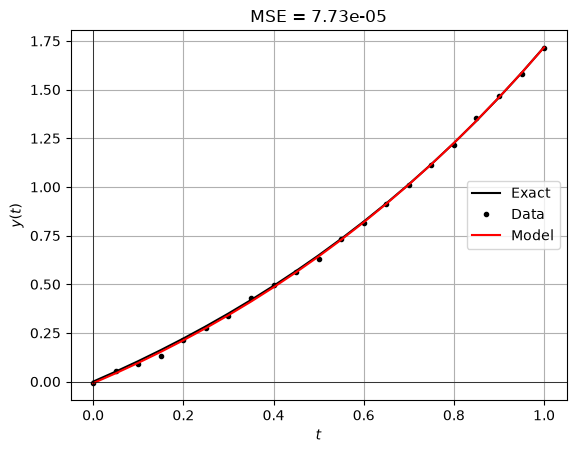

In [34]:
params = pattern_search()
ts_model, ys_model = compute_curve(**params)
mse = MSE(**params)

plt.plot(ts_exact, ys_exact, '-k', label='Exact')
plt.plot(ts_data, ys_data, '.k', label='Data')
plt.plot(ts_model, ys_model, '-r', label='Model')
plt.axhline(0.0, lw=0.5, color='k'); plt.axvline(0.0, lw=0.5, color='k')
plt.grid(True); plt.legend()
plt.xlabel('$t$'); plt.ylabel('$y(t)$')
plt.title(f'MSE = {mse:8.2e}')
plt.show()

In [35]:
n, k = len(ys_model), len(params)
BIC  = n * log(mse) + k * log(n)
AIC  = n * log(mse) + k * 2.0
AICc = n * log(mse) + k * 2.0 * n/(n-k-1)

print("MODEL: dy/dt = a * y² + b")
for key, val in params.items():
    print(f'* {key:>2s} = {val:9.6f}')
print(f"{BIC  = :.1f}")
print(f"{AIC  = :.1f}")
print(f"{AICc = :.1f}")

MODEL: dy/dt = a * y² + b
*  a = -0.058176
*  b =  1.084567
*  c =  0.995207
* y0 = -0.007952
BIC  = -186.7
AIC  = -190.8
AICc = -188.3
